<a href="https://colab.research.google.com/github/carolinaaraujo-cap/C-lculo-Num-rico/blob/main/Atividade_Gauss_Seidel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MÉTODO DE GAUSS–SEIDEL
Número de iterações : 6
Solução aproximada  : x = 1.00000003
                      y = 1.99999998
                      z = -1.00000001
Solução (numpy)     : [ 1.  2. -1.]
Erro máx. vs exata  : 2.69e-08
Resíduo ||Ax-b||_inf: 2.81e-07


k,x(k),y(k),z(k),‖x(k) − x(k−1)‖∞
0,0.00000000,0.00000000,0.00000000,—
1,0.60000000,2.05454545,-0.91454545,2.055e+00
2,0.98836364,2.00671074,-0.99700165,3.884e-01
3,1.00007140,2.00027907,-0.99998637,1.171e-02
4,1.00002518,2.00000353,-1.00000468,2.755e-04
5,1.00000129,1.99999969,-1.00000029,2.389e-05
6,1.00000003,1.99999998,-1.00000001,1.263e-06


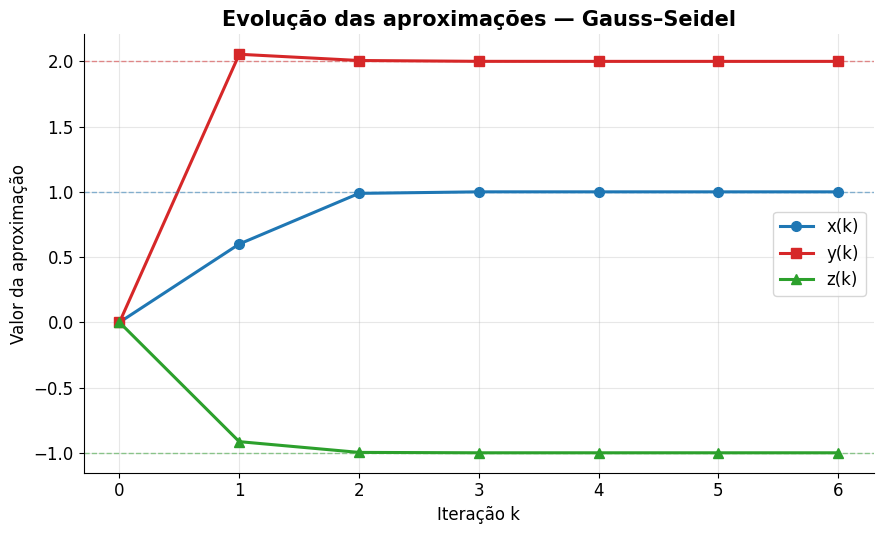

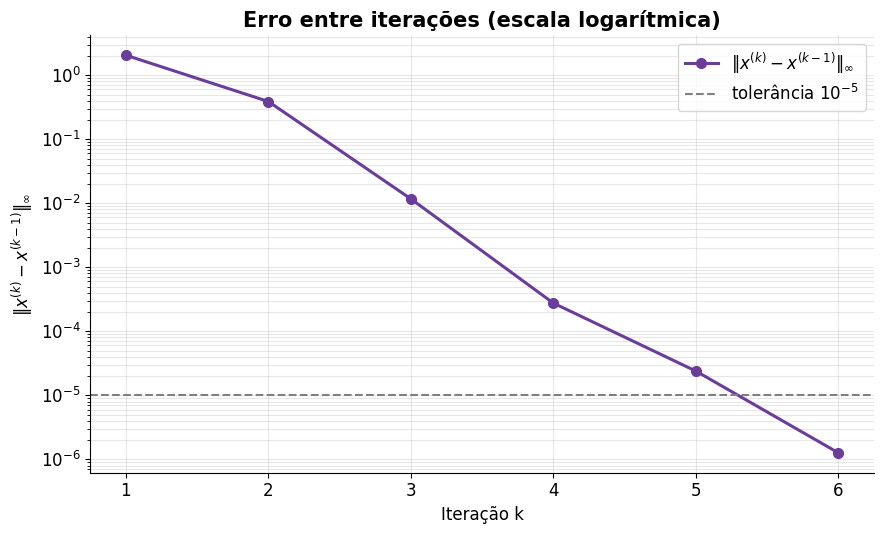

In [8]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Sistema linear  Ax = b
#   10x -  y +  2z =   6
#   -x + 11y -  z  =  22
#   2x -  y + 10z  = -10
# ------------------------------------------------------------
A = np.array([[10.0, -1.0,  2.0],
              [-1.0, 11.0, -1.0],
              [ 2.0, -1.0, 10.0]])
b = np.array([6.0, 22.0, -10.0])


def gauss_seidel(A, b, x0, tol=1e-5, max_iter=1000):

    n = len(b)
    x = x0.astype(float).copy()
    historico = [{"k": 0, "x": x[0], "y": x[1], "z": x[2], "erro": np.nan}]

    for k in range(1, max_iter + 1):
        x_antigo = x.copy()

        for i in range(n):
            # usa valores JÁ ATUALIZADOS (j < i) e valores ANTIGOS (j > i)
            soma = sum(A[i, j] * x[j] for j in range(n) if j != i)
            x[i] = (b[i] - soma) / A[i, i]

        erro = np.max(np.abs(x - x_antigo))          # norma infinito
        historico.append({"k": k, "x": x[0], "y": x[1], "z": x[2], "erro": erro})

        if erro < tol:
            break

    return historico


x0 = np.array([0.0, 0.0, 0.0])
hist = gauss_seidel(A, b, x0, tol=1e-5)

n_iter = hist[-1]["k"]
solucao = np.array([hist[-1]["x"], hist[-1]["y"], hist[-1]["z"]])

print("=" * 52)
print("MÉTODO DE GAUSS–SEIDEL")
print("=" * 52)
print(f"Número de iterações : {n_iter}")
print(f"Solução aproximada  : x = {solucao[0]:.8f}")
print(f"                      y = {solucao[1]:.8f}")
print(f"                      z = {solucao[2]:.8f}")

# Conferência com a solução exata (numpy)
exata = np.linalg.solve(A, b)
print(f"Solução (numpy)     : {exata}")
print(f"Erro máx. vs exata  : {np.max(np.abs(solucao - exata)):.2e}")
print(f"Resíduo ||Ax-b||_inf: {np.max(np.abs(A @ solucao - b)):.2e}")

#Tabela
df = pd.DataFrame(hist)
df.columns = ["k", "x(k)", "y(k)", "z(k)", "‖x(k) − x(k−1)‖∞"]
col_erro = "‖x(k) − x(k−1)‖∞"
ultima = df.index[-1]


def zebrado(linha):
    """Fundo alternado (azul claro / branco) aplicado célula a célula."""
    cor = "#eaf1f8" if linha.name % 2 == 1 else "#ffffff"
    return [f"background-color: {cor}"] * len(linha)


def destaca_linhas(linha):
    """Linha inicial em cinza e linha final (solução) em verde."""
    if linha.name == 0:
        return ["background-color: #eceff1; color: #546e7a; font-style: italic"] * len(linha)
    if linha.name == ultima:
        return ["background-color: #c8e6c9; color: #1b5e20; font-weight: bold"] * len(linha)
    return [""] * len(linha)


tabela_estilizada = (
    df.style
      .format({"x(k)": "{:.8f}", "y(k)": "{:.8f}", "z(k)": "{:.8f}",
               col_erro: "{:.3e}"}, na_rep="—")
      .hide(axis="index")
      .apply(zebrado, axis=1)
      # degradê roxo na coluna do erro (escala logarítmica: quanto menor, mais claro)
      .background_gradient(cmap="Purples", subset=[col_erro],
                           gmap=np.log10(df[col_erro].astype(float)),
                           vmin=-8, vmax=1, high=0.55)  # high: mantém as cores claras p/ legibilidade
      .apply(destaca_linhas, axis=1)
      .set_caption("Iterações do método de Gauss–Seidel &nbsp;·&nbsp; "
                   "x⁽⁰⁾ = (0, 0, 0) &nbsp;·&nbsp; tolerância 10⁻⁵")
      .set_table_styles([
          {"selector": "", "props": [("border-collapse", "collapse"),
                                     ("margin", "16px auto"),
                                     ("font-family", "'Roboto Mono', 'Courier New', monospace"),
                                     ("font-size", "14px"),
                                     ("box-shadow", "0 2px 10px rgba(0,0,0,0.15)")]},
          {"selector": "caption", "props": [("caption-side", "top"),
                                            ("font-family", "sans-serif"),
                                            ("font-size", "17px"),
                                            ("font-weight", "bold"),
                                            ("color", "#1f4e79"),
                                            ("padding", "10px")]},
          {"selector": "th", "props": [("background-color", "#1f4e79"),
                                       ("color", "white"),
                                       ("text-align", "center"),
                                       ("padding", "10px 18px"),
                                       ("font-family", "sans-serif")]},
          {"selector": "td", "props": [("text-align", "center"),
                                       ("padding", "8px 18px"),
                                       ("color", "#1b1f24"),
                                       ("border-bottom", "1px solid #d0d7de")]},
          {"selector": "tbody tr:hover td", "props": [("background-color", "#fff3cd !important")]},
      ])
)

# Exibe a tabela estilizada no Colab/Jupyter
try:
    from IPython.display import display
    display(tabela_estilizada)
except ImportError:
    pass


# ------------------------------------------------------------
# ITEM 7 - Gráficos
# ------------------------------------------------------------
plt.rcParams.update({
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

ks = df["k"].to_numpy()

# (a) x(k), y(k) e z(k) em função de k, no mesmo gráfico
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(ks, df["x(k)"], "o-", color="#1f77b4", lw=2.2, ms=7, label="x(k)")
ax.plot(ks, df["y(k)"], "s-", color="#d62728", lw=2.2, ms=7, label="y(k)")
ax.plot(ks, df["z(k)"], "^-", color="#2ca02c", lw=2.2, ms=7, label="z(k)")

# linhas tracejadas com a solução exata
for val, cor in zip(exata, ["#1f77b4", "#d62728", "#2ca02c"]):
    ax.axhline(val, color=cor, ls="--", lw=1, alpha=0.5)

ax.set_title("Evolução das aproximações — Gauss–Seidel", fontsize=15, weight="bold")
ax.set_xlabel("Iteração k")
ax.set_ylabel("Valor da aproximação")
ax.set_xticks(ks)
ax.legend(frameon=True, fontsize=12, loc="center right")
fig.tight_layout()
fig.savefig("grafico_a_aproximacoes.png", dpi=200)
plt.show()

# (b) erro entre iterações em escala logarítmica
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.semilogy(ks[1:], df["‖x(k) − x(k−1)‖∞"].to_numpy()[1:],
            "o-", color="#6a3d9a", lw=2.2, ms=7, label=r"$\|x^{(k)}-x^{(k-1)}\|_\infty$")
ax.axhline(1e-5, color="gray", ls="--", lw=1.5, label=r"tolerância $10^{-5}$")

ax.set_title("Erro entre iterações (escala logarítmica)", fontsize=15, weight="bold")
ax.set_xlabel("Iteração k")
ax.set_ylabel(r"$\|x^{(k)}-x^{(k-1)}\|_\infty$")
ax.set_xticks(ks[1:])
ax.grid(True, which="both", alpha=0.3)
ax.legend(frameon=True, fontsize=12)
fig.tight_layout()
fig.savefig("grafico_b_erro.png", dpi=200)
plt.show()